Analyze data:

In [23]:
import pandas as pd

In [24]:
df = pd.read_csv("../data/GermanCreditESMT.csv")


In [25]:
# First 5 rows
print(df.head())

# Count missing values
df.info()

# Check data types
print(df.dtypes)

# Check shape and what columns we have got
print(df.shape)
print(df.columns)

                status  duration                               credit_history  \
0  no checking account        18      all credits at this bank paid back duly   
1  no checking account         9      all credits at this bank paid back duly   
2           ... < 0 DM        12  no credits taken/all credits paid back duly   
3  no checking account        12      all credits at this bank paid back duly   
4  no checking account        12      all credits at this bank paid back duly   

      purpose  amount                     savings employment_duration  \
0  car (used)    1049  unknown/no savings account              < 1 yr   
1      others    2799  unknown/no savings account    1 <= ... < 4 yrs   
2  retraining     841               ... <  100 DM    4 <= ... < 7 yrs   
3      others    2122  unknown/no savings account    1 <= ... < 4 yrs   
4      others    2171  unknown/no savings account    1 <= ... < 4 yrs   

  installment_rate                   personal_status_sex other_debtors  ..

In [26]:
# Distribution of the outcome
# Replace "credit_risk" with the actual target column name from df.columns
target = "credit_risk"
print(df[target].value_counts())
print(df[target].value_counts(normalize=True).round(3))

# Distribution of the features
print(df.describe())                      # numeric features
print(df.describe(include="object"))      # categorical features

credit_risk
good    700
bad     300
Name: count, dtype: int64
credit_risk
good    0.7
bad     0.3
Name: proportion, dtype: float64
          duration       amount         age
count  1000.000000   1000.00000  1000.00000
mean     20.903000   3271.24800    35.54200
std      12.058814   2822.75176    11.35267
min       4.000000    250.00000    19.00000
25%      12.000000   1365.50000    27.00000
50%      18.000000   2319.50000    33.00000
75%      24.000000   3972.25000    42.00000
max      72.000000  18424.00000    75.00000
                                            status  \
count                                         1000   
unique                                           4   
top     ... >= 200 DM / salary for at least 1 year   
freq                                           394   

                                     credit_history              purpose  \
count                                          1000                 1000   
unique                                            

C:\Users\luis_\AppData\Local\Temp\ipykernel_25616\3572681658.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.describe(include="object"))      # categorical features


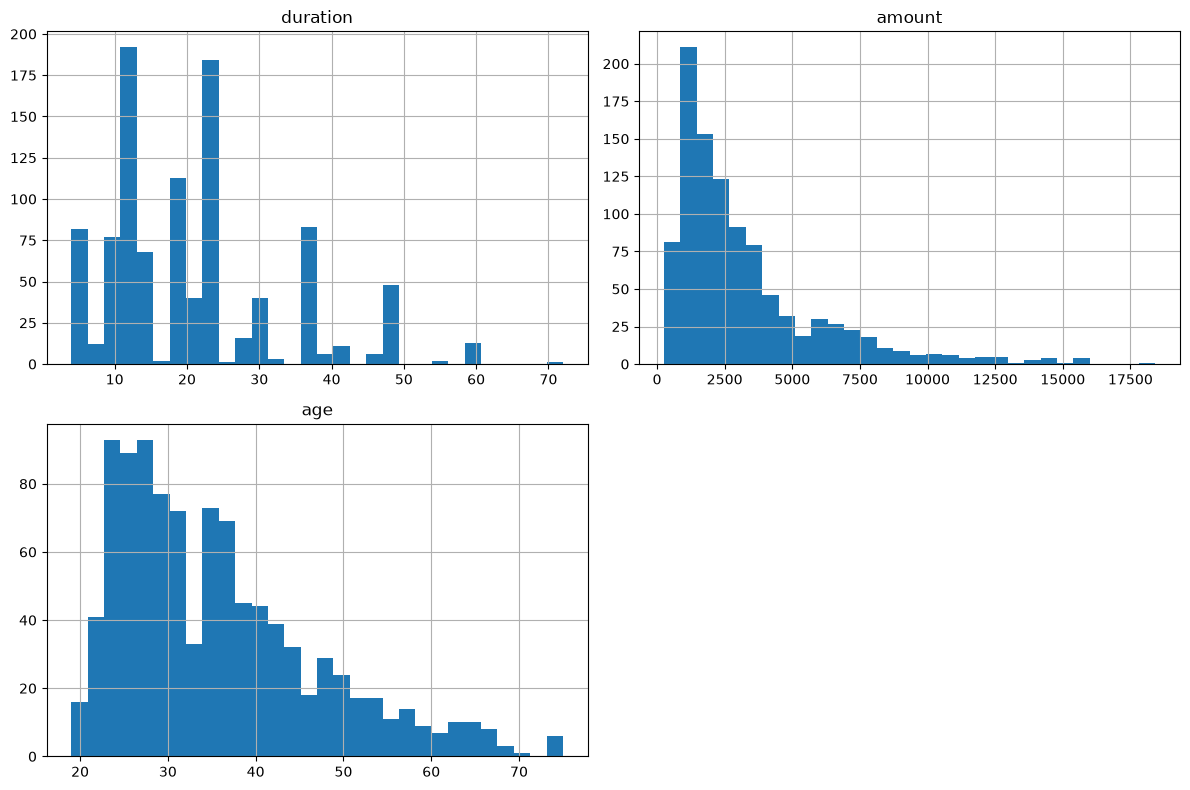

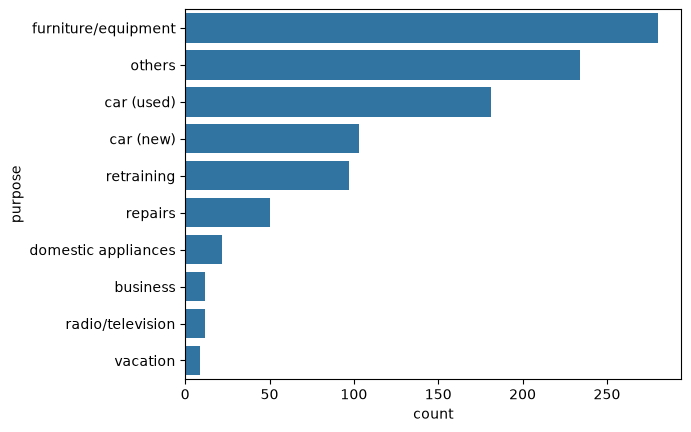

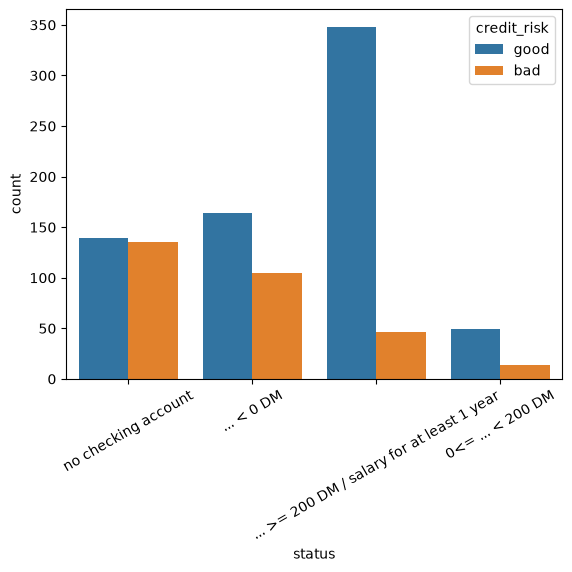

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# Numeric features: histograms
df.hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()

# One categorical feature: counts
sns.countplot(data=df, y="purpose", order=df["purpose"].value_counts().index)
plt.show()

# Outcome by a feature
sns.countplot(data=df, x="status", hue=target)
plt.xticks(rotation=30)
plt.show()

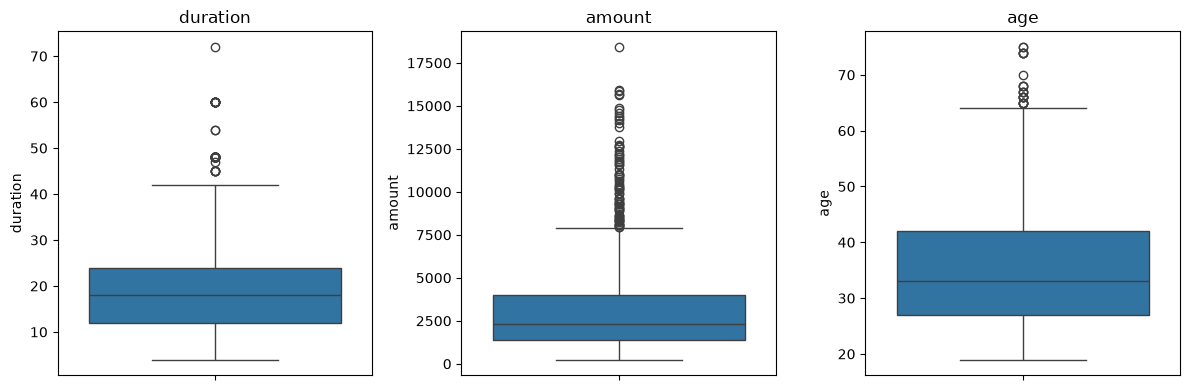

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, col in zip(axes, ["duration", "amount", "age"]):
    sns.boxplot(data=df, y=col, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

Task:
- Histogram plot if not yet included
- Smart countplots for the categories
- Turn every category into l-1 yes/no columns to prepare the data for modeling

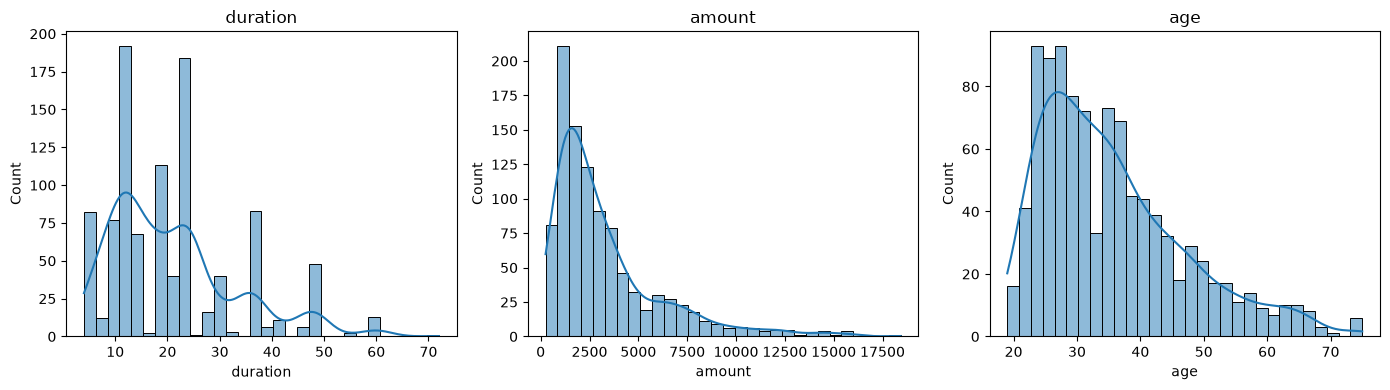

In [29]:
# Histograms
num_cols = ["duration", "amount", "age"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, bins=30, kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

C:\Users\luis_\AppData\Local\Temp\ipykernel_25616\3042762769.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = [c for c in df.select_dtypes("object").columns if c != target]


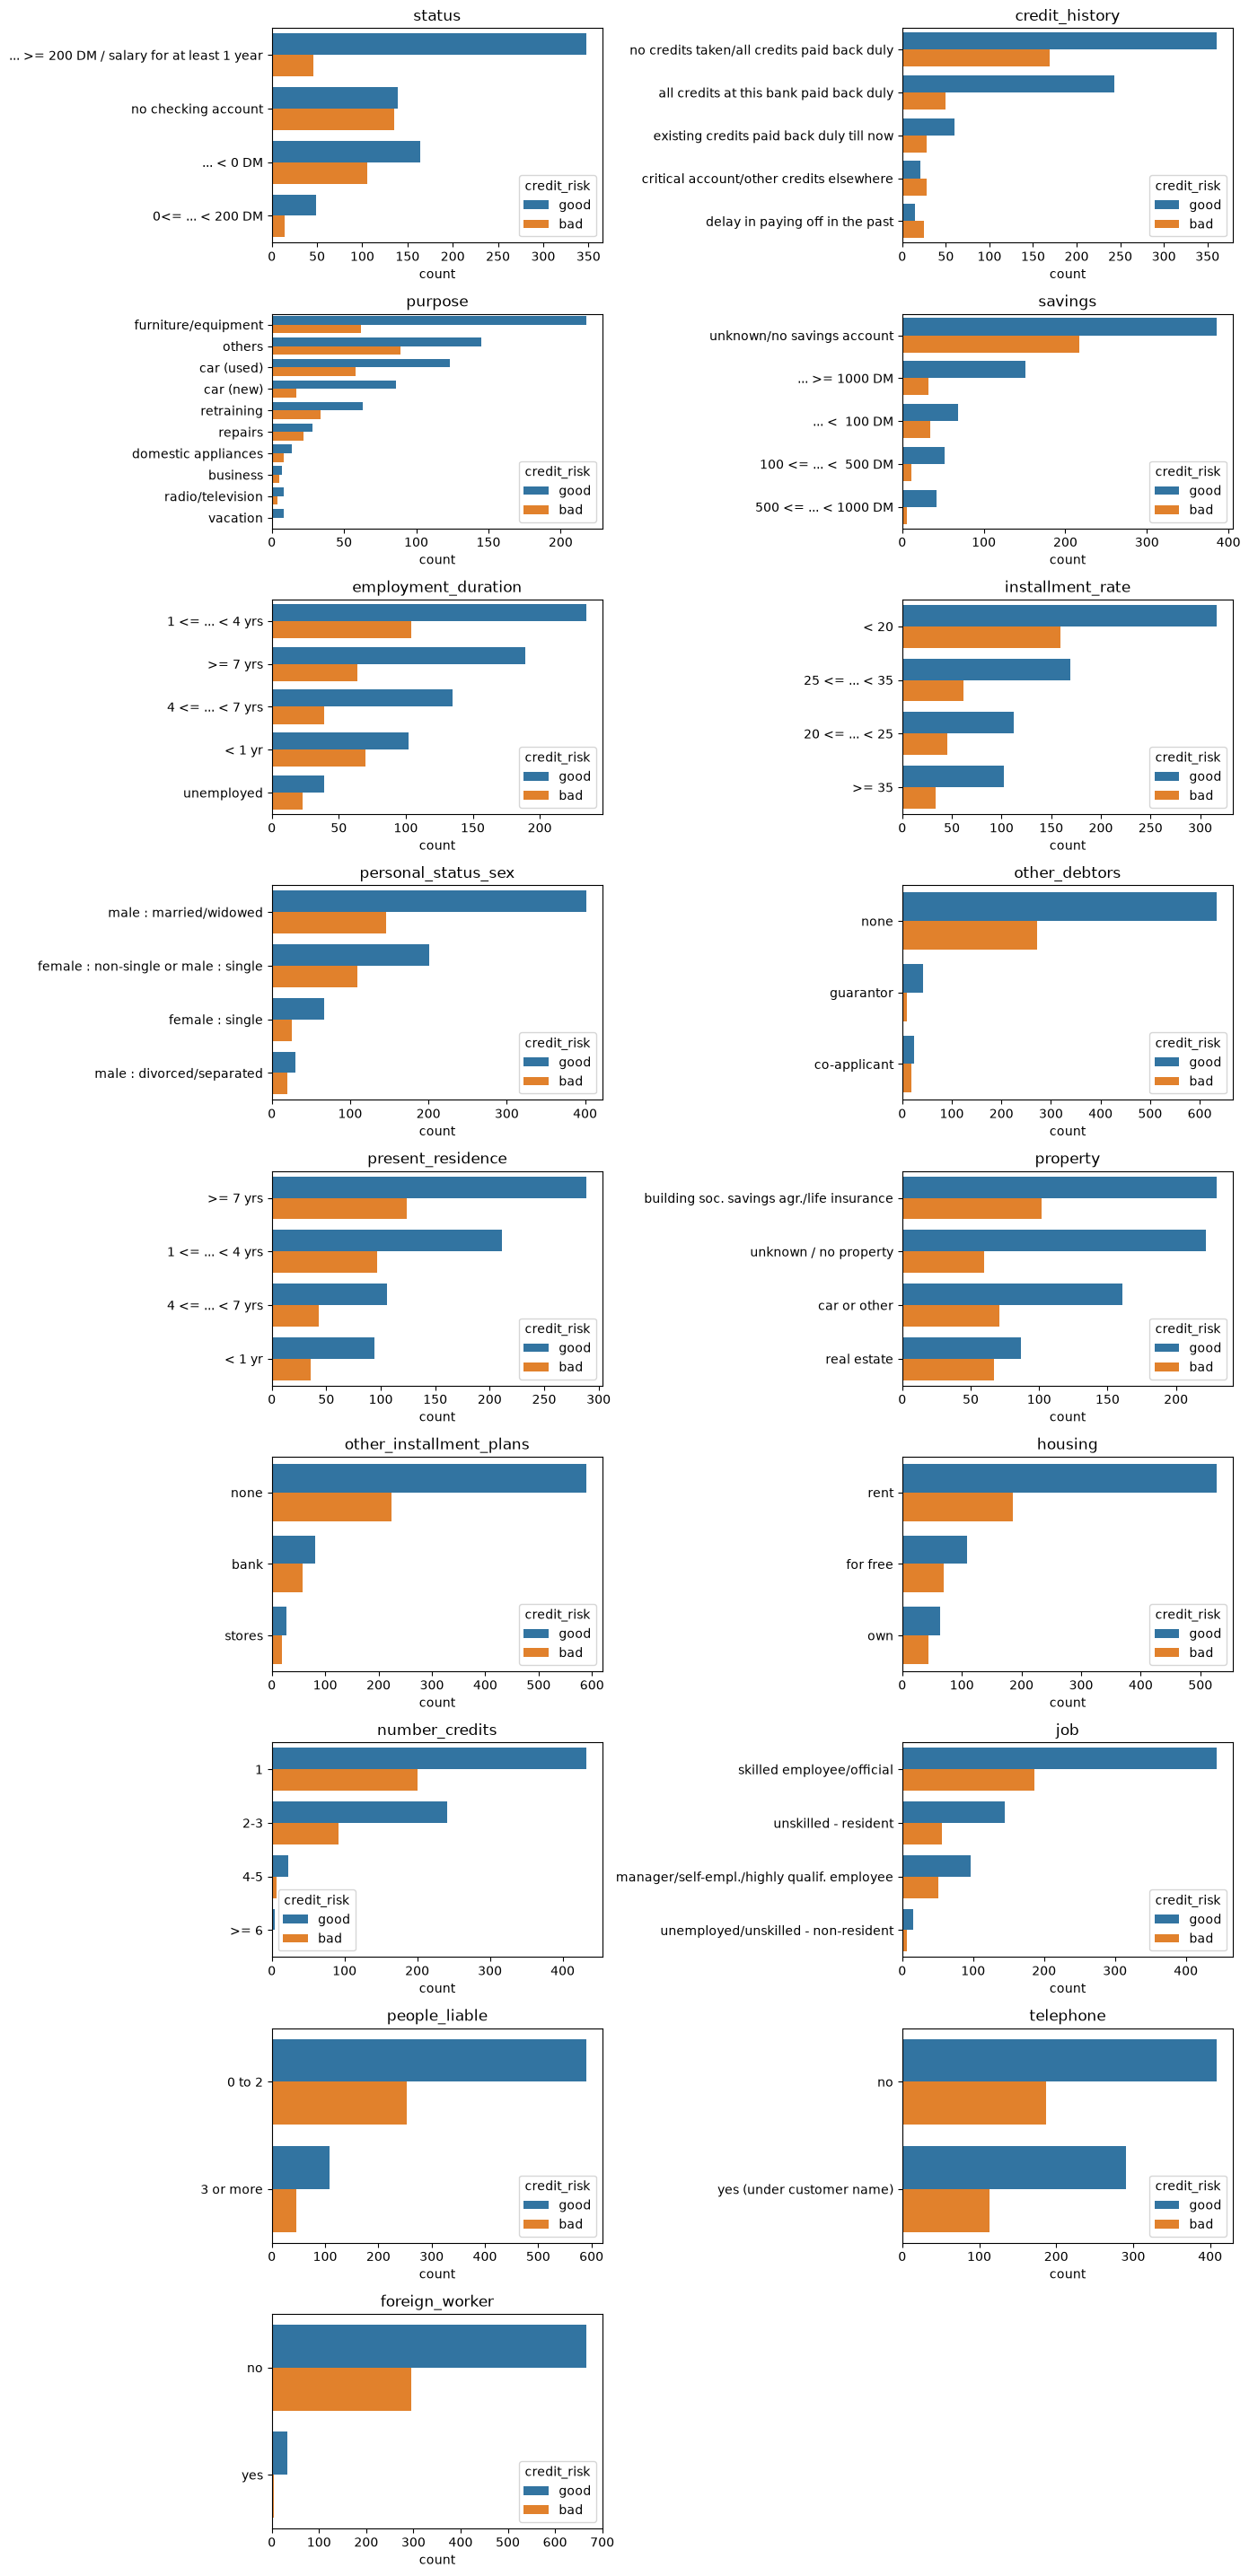

In [30]:
# Smart counterplots for the categories
target = "credit_risk"   # replace with your actual target column
cat_cols = [c for c in df.select_dtypes("object").columns if c != target]

n_cols = 2
n_rows = -(-len(cat_cols) // n_cols)          # ceiling division
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 3.2 * n_rows))

for ax, col in zip(axes.flat, cat_cols):
    order = df[col].value_counts().index
    sns.countplot(data=df, y=col, order=order, hue=target, ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")

for ax in axes.flat[len(cat_cols):]:           # hide unused panels
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [31]:
X = pd.get_dummies(
    df.drop(columns=[target]),
    columns=cat_cols,
    drop_first=True,
    dtype=int,        # 0/1 instead of True/False
)
y = df[target]

print(X.shape)
print(X.columns.tolist())

(1000, 54)
['duration', 'amount', 'age', 'status_... >= 200 DM / salary for at least 1 year', 'status_0<= ... < 200 DM', 'status_no checking account', 'credit_history_critical account/other credits elsewhere', 'credit_history_delay in paying off in the past', 'credit_history_existing credits paid back duly till now', 'credit_history_no credits taken/all credits paid back duly', 'purpose_car (new)', 'purpose_car (used)', 'purpose_domestic appliances', 'purpose_furniture/equipment', 'purpose_others', 'purpose_radio/television', 'purpose_repairs', 'purpose_retraining', 'purpose_vacation', 'savings_... >= 1000 DM', 'savings_100 <= ... <  500 DM', 'savings_500 <= ... < 1000 DM', 'savings_unknown/no savings account', 'employment_duration_4 <= ... < 7 yrs', 'employment_duration_< 1 yr', 'employment_duration_>= 7 yrs', 'employment_duration_unemployed', 'installment_rate_25 <= ... < 35', 'installment_rate_< 20', 'installment_rate_>= 35', 'personal_status_sex_female : single', 'personal_status_s